# Comprehensive K-Means Clustering Analysis
**End-to-End Machine Learning Pipeline on Real-World Data (Iris Dataset)**

This notebook covers the complete lifecycle of an unsupervised clustering project:
1. **Data Loading & Initial Inspection**
2. **Pre-EDA (Exploratory Data Analysis before Modeling)**
3. **Train-Test Split & Feature Scaling (Preventing Data Leakage)**
4. **K-Means vs. K-Means++ Initialization Comparison**
5. **Elbow Method with Train-Test Curves (Finding Optimal $K$)**
6. **Final Model Training & Post-EDA (Visualizing Clusters & Centroids)**
7. **Evaluation & "Accuracy" Metrics (Silhouette Score, ARI, NMI, Mapped Accuracy)**
8. **Manual Prediction on Unseen Data with Distance Vector Diagram**

## 1. Import Libraries & Load Real Dataset
We use the classic **Iris botanical dataset**, which contains real-world measurements of petal and sepal dimensions across three species (*Setosa*, *Versicolor*, and *Virginica*).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mode

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix
)

# Set visual styling
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# Load real-world Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['true_species'] = iris.target
df['species_name'] = df['true_species'].map({0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'})

print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),true_species,species_name
0,5.1,3.5,1.4,0.2,0,Setosa
1,4.9,3.0,1.4,0.2,0,Setosa
2,4.7,3.2,1.3,0.2,0,Setosa
3,4.6,3.1,1.5,0.2,0,Setosa
4,5.0,3.6,1.4,0.2,0,Setosa


## 2. Pre-EDA (Exploratory Data Analysis Before Clustering)
Before applying any algorithm, we inspect summary statistics, feature correlations, and raw unclustered distributions to understand the natural structure of the data.

=== Statistical Summary (Pre-EDA) ===


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),true_species
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00



=== Missing Values Check ===
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
true_species         0
species_name         0
dtype: int64


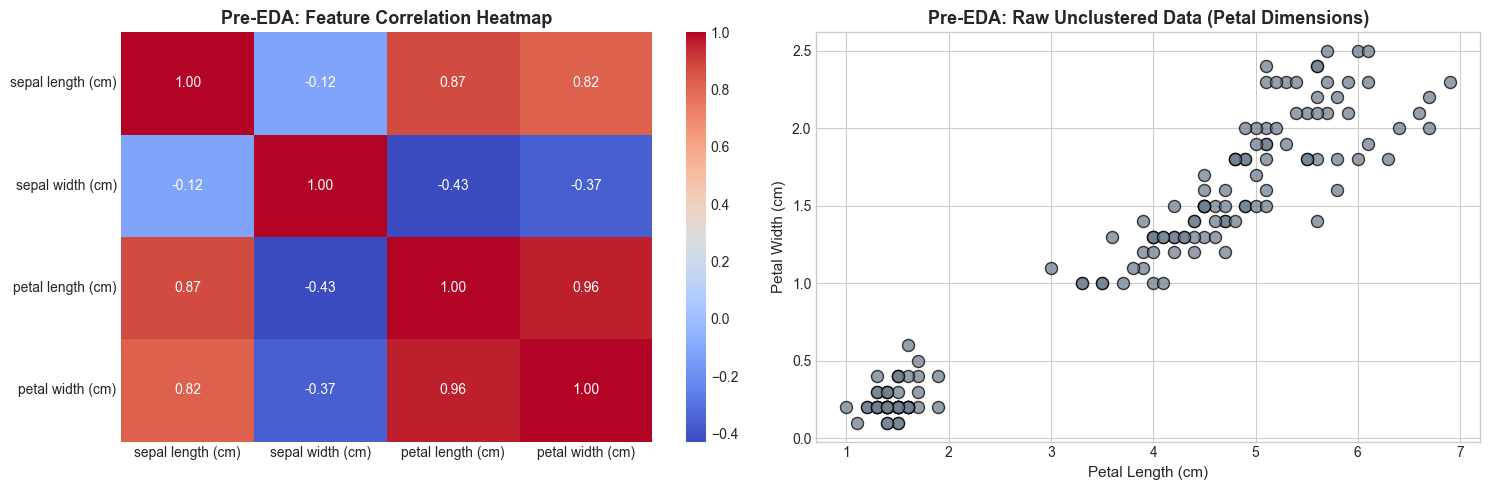

In [2]:
# 1. Summary Statistics
print("=== Statistical Summary (Pre-EDA) ===")
display(df.describe().round(2))

# 2. Check for Missing Values
print("\n=== Missing Values Check ===")
print(df.isnull().sum())

# 3. Pre-EDA Visualizations: Correlation Heatmap & Raw Unclustered Scatter Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Correlation Matrix
corr_matrix = df[iris.feature_names].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0], cbar=True)
axes[0].set_title('Pre-EDA: Feature Correlation Heatmap', fontsize=13, fontweight='bold')

# Raw Unclustered Scatter Plot (Petal Length vs Petal Width)
axes[1].scatter(
    df['petal length (cm)'],
    df['petal width (cm)'],
    c='slategray',
    edgecolors='black',
    s=75,
    alpha=0.75
)
axes[1].set_title('Pre-EDA: Raw Unclustered Data (Petal Dimensions)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Petal Length (cm)', fontsize=11)
axes[1].set_ylabel('Petal Width (cm)', fontsize=11)

plt.tight_layout()
plt.show()

## 3. Train-Test Split & Feature Scaling
To evaluate how well our clusters generalize to **unseen data** without data leakage:
* We split the dataset into **80% Training** and **20% Testing**.
* We fit `StandardScaler` **strictly on the training set** and apply that transformation to the test set. K-Means relies on Euclidean distance, so scaling ensures all features contribute equally.

In [3]:
# Select Petal Length and Petal Width for clear 2D clustering & visualization
features = ['petal length (cm)', 'petal width (cm)']
X = df[features].values
y = df['true_species'].values

# Split into Train (80%) and Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale features (Fit ONLY on X_train to prevent data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")

Training Samples: 120 | Testing Samples: 30


## 4. Effect of Standard K-Means (`random`) vs. `K-Means++`
* **Standard K-Means (`init='random'`)**: Picks initial centroids completely at random. Poor random starting points can trap the algorithm in suboptimal clusters or require more iterations to converge.
* **K-Means++ (`init='k-means++'`)**: Selects initial centroids far apart from one another using a weighted probability distribution, leading to faster convergence and consistently lower inertia (within-cluster variance).

Let's run 20 single-initialization trials (`n_init=1`) to observe the direct impact of initialization!

,Metric,Standard K-Means (random),K-Means++ (k-means++)
0,Mean Inertia (Lower = Better),13.844,13.844
1,Max/Worst Inertia (Instability),13.844,13.844
2,Mean Iterations to Converge,6.200,3.700


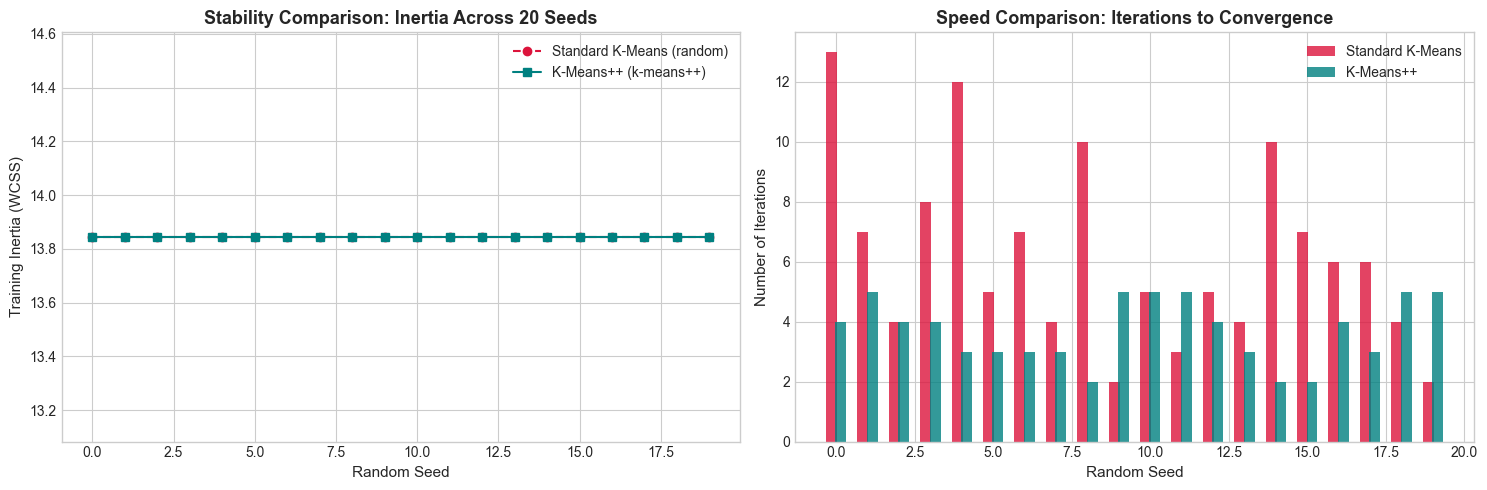

In [4]:
# Compare Random Initialization vs K-Means++ across 20 different random seeds
seeds = range(20)
random_inertias = []
kmeans_pp_inertias = []
random_iters = []
kmeans_pp_iters = []

for seed in seeds:
    # Standard K-Means (Random Init, single run)
    km_rand = KMeans(n_clusters=3, init='random', n_init=1, random_state=seed)
    km_rand.fit(X_train_scaled)
    random_inertias.append(km_rand.inertia_)
    random_iters.append(km_rand.n_iter_)

    # K-Means++ (Smart Init, single run)
    km_pp = KMeans(n_clusters=3, init='k-means++', n_init=1, random_state=seed)
    km_pp.fit(X_train_scaled)
    kmeans_pp_inertias.append(km_pp.inertia_)
    kmeans_pp_iters.append(km_pp.n_iter_)

# Summary Table
comparison_df = pd.DataFrame({
    'Metric': ['Mean Inertia (Lower = Better)', 'Max/Worst Inertia (Instability)', 'Mean Iterations to Converge'],
    'Standard K-Means (random)': [np.mean(random_inertias), np.max(random_inertias), np.mean(random_iters)],
    'K-Means++ (k-means++)': [np.mean(kmeans_pp_inertias), np.max(kmeans_pp_inertias), np.mean(kmeans_pp_iters)]
})
display(comparison_df.round(3))

# Visual Comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Inertia Stability across Seeds
axes[0].plot(seeds, random_inertias, marker='o', linestyle='--', color='crimson', label='Standard K-Means (random)')
axes[0].plot(seeds, kmeans_pp_inertias, marker='s', linestyle='-', color='teal', label='K-Means++ (k-means++)')
axes[0].set_title('Stability Comparison: Inertia Across 20 Seeds', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Random Seed', fontsize=11)
axes[0].set_ylabel('Training Inertia (WCSS)', fontsize=11)
axes[0].legend()

# Plot 2: Iterations Needed to Converge
axes[1].bar(np.array(seeds) - 0.15, random_iters, width=0.35, color='crimson', alpha=0.8, label='Standard K-Means')
axes[1].bar(np.array(seeds) + 0.15, kmeans_pp_iters, width=0.35, color='teal', alpha=0.8, label='K-Means++')
axes[1].set_title('Speed Comparison: Iterations to Convergence', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Random Seed', fontsize=11)
axes[1].set_ylabel('Number of Iterations', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Elbow Method with Train-Test Curves (Finding Optimal $K$)
To determine the optimal number of clusters $K$ programmatically, we evaluate inertia across $K = 1$ to $10$ on both the **Training Set** and the **Unseen Test Set**. Look for the sharp bend ("elbow") where the reduction in inertia slows down dramatically.

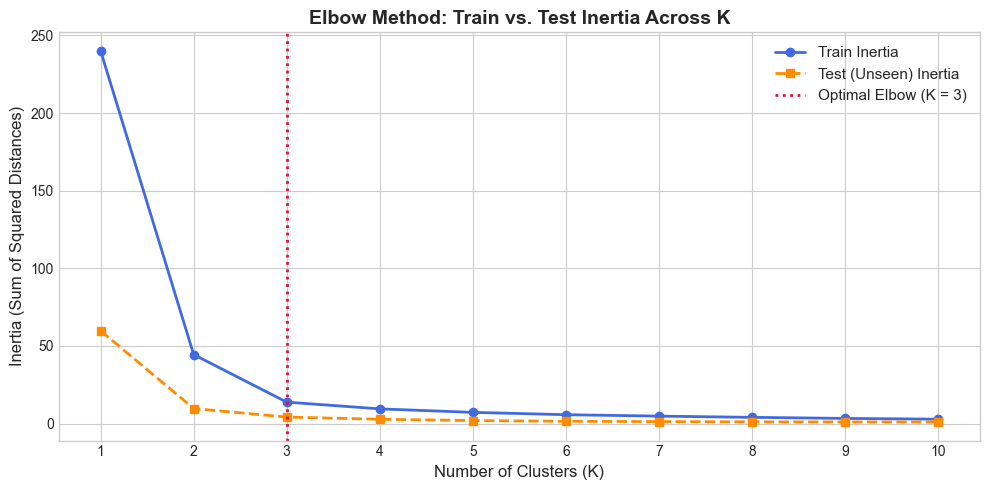

In [5]:
k_range = range(1, 11)
train_inertias = []
test_inertias = []

for k in k_range:
    model = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    model.fit(X_train_scaled)
    
    # Training Inertia
    train_inertias.append(model.inertia_)
    
    # Unseen Test Set Inertia
    test_labels = model.predict(X_test_scaled)
    test_inertia = np.sum((X_test_scaled - model.cluster_centers_[test_labels]) ** 2)
    test_inertias.append(test_inertia)

plt.figure(figsize=(10, 5))
plt.plot(k_range, train_inertias, marker='o', linewidth=2, color='royalblue', label='Train Inertia')
plt.plot(k_range, test_inertias, marker='s', linewidth=2, linestyle='--', color='darkorange', label='Test (Unseen) Inertia')
plt.axvline(x=3, color='crimson', linestyle=':', linewidth=2, label='Optimal Elbow (K = 3)')

plt.title('Elbow Method: Train vs. Test Inertia Across K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.xticks(k_range)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## 6. Post-EDA: Visualizing Discovered Clusters & Centroids
Now we train our final `K-Means++` model with $K=3$ on the training set, predict clusters on the unseen test set, and visualize how the data transformed from an unclustered cloud (Pre-EDA) into structured segments (Post-EDA).

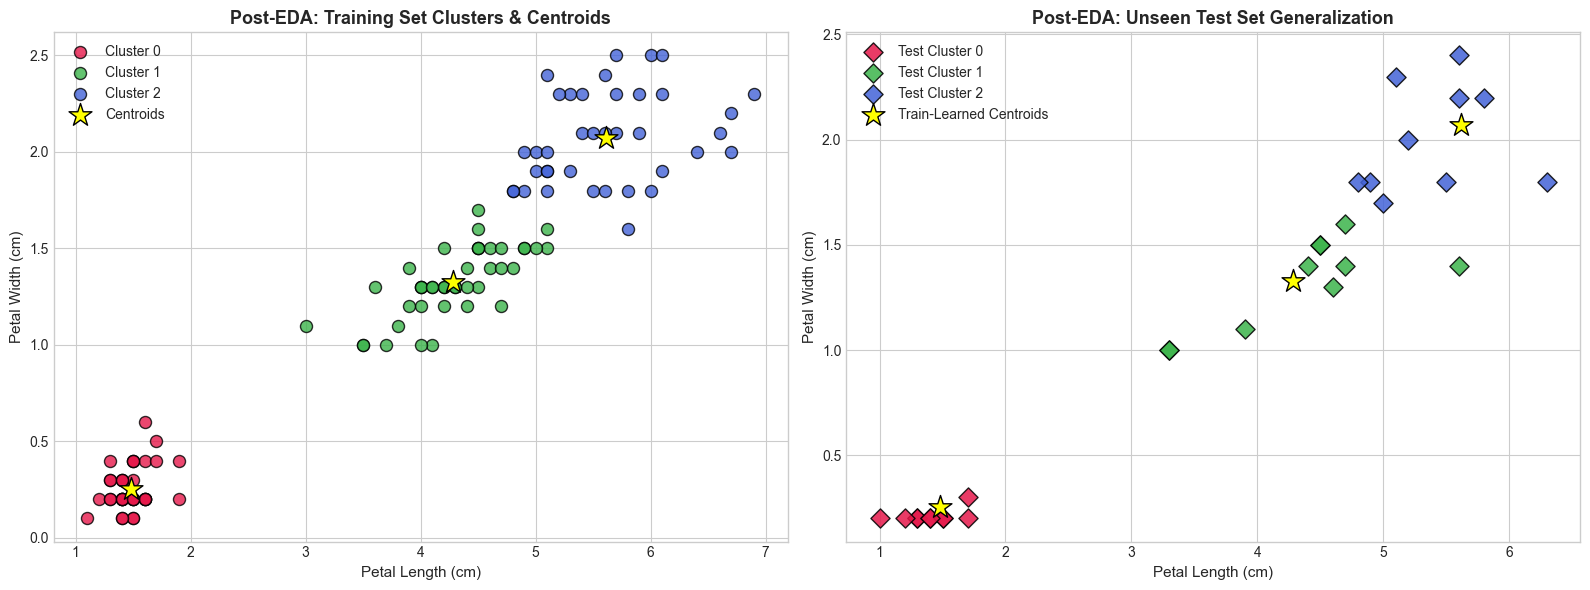

In [6]:
# Fit final K-Means++ model
final_kmeans = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
train_clusters = final_kmeans.fit_predict(X_train_scaled)
test_clusters = final_kmeans.predict(X_test_scaled)

# Inverse transform centroids back to original cm scale for plotting
centroids_original = scaler.inverse_transform(final_kmeans.cluster_centers_)

# Side-by-side Post-EDA Visualization (Train vs Test Clusters)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = ['#e6194b', '#3cb44b', '#4363d8']

# Left Plot: Training Set Clusters
for i in range(3):
    pts = X_train[train_clusters == i]
    axes[0].scatter(pts[:, 0], pts[:, 1], s=75, c=colors[i], label=f'Cluster {i}', edgecolors='k', alpha=0.8)

axes[0].scatter(centroids_original[:, 0], centroids_original[:, 1], s=300, c='yellow', marker='*', edgecolors='black', label='Centroids')
axes[0].set_title('Post-EDA: Training Set Clusters & Centroids', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Petal Length (cm)', fontsize=11)
axes[0].set_ylabel('Petal Width (cm)', fontsize=11)
axes[0].legend()

# Right Plot: Unseen Test Set Clusters
for i in range(3):
    pts = X_test[test_clusters == i]
    axes[1].scatter(pts[:, 0], pts[:, 1], s=95, c=colors[i], label=f'Test Cluster {i}', edgecolors='k', marker='D', alpha=0.85)

axes[1].scatter(centroids_original[:, 0], centroids_original[:, 1], s=300, c='yellow', marker='*', edgecolors='black', label='Train-Learned Centroids')
axes[1].set_title('Post-EDA: Unseen Test Set Generalization', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Petal Length (cm)', fontsize=11)
axes[1].set_ylabel('Petal Width (cm)', fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Evaluation & Accuracy Metrics (Train vs. Test)
Because K-Means is unsupervised, we evaluate it using:
1. **Silhouette Score** ($-1$ to $+1$): Measures cluster cohesion and separation without needing ground-truth labels.
2. **Adjusted Rand Index (ARI)** & **Normalized Mutual Information (NMI)**: Compare discovered clusters against true botanical species.
3. **Mapped Classification Accuracy**: Aligns each cluster ID with its majority true species label to compute standard percentage accuracy on both Train and Unseen Test sets.

,Metric,Train Set (80%),Unseen Test Set (20%)
0,Silhouette Score (Unsupervised),0.6866,0.6133
1,Adjusted Rand Index (ARI),0.9034,0.8067
2,Normalized Mutual Info (NMI),0.8833,0.8027
3,Mapped Accuracy (%),96.67%,93.33%


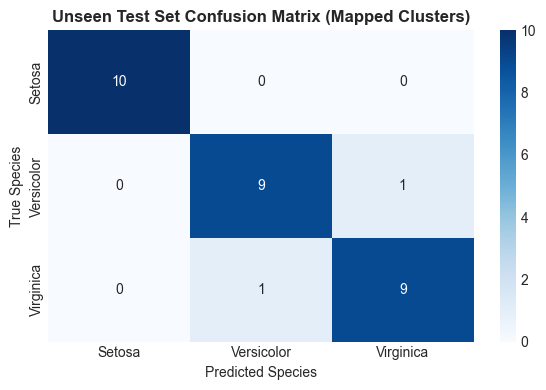

In [7]:
def evaluate_clustering(X_scaled, clusters, y_true, cluster_to_label_map=None):
    sil = silhouette_score(X_scaled, clusters)
    ari = adjusted_rand_score(y_true, clusters)
    nmi = normalized_mutual_info_score(y_true, clusters)
    
    # Learn label mapping from training set if not provided
    if cluster_to_label_map is None:
        cluster_to_label_map = {}
        for i in range(3):
            mask = (clusters == i)
            cluster_to_label_map[i] = mode(y_true[mask], keepdims=True).mode[0]
            
    mapped_preds = np.array([cluster_to_label_map[c] for c in clusters])
    acc = np.mean(mapped_preds == y_true) * 100
    return sil, ari, nmi, acc, cluster_to_label_map, mapped_preds

# Evaluate on Train Set
train_sil, train_ari, train_nmi, train_acc, label_map, _ = evaluate_clustering(
    X_train_scaled, train_clusters, y_train
)

# Evaluate on Unseen Test Set using the Train-learned label map
test_sil, test_ari, test_nmi, test_acc, _, test_mapped_preds = evaluate_clustering(
    X_test_scaled, test_clusters, y_test, cluster_to_label_map=label_map
)

metrics_df = pd.DataFrame({
    'Metric': ['Silhouette Score (Unsupervised)', 'Adjusted Rand Index (ARI)', 'Normalized Mutual Info (NMI)', 'Mapped Accuracy (%)'],
    'Train Set (80%)': [f"{train_sil:.4f}", f"{train_ari:.4f}", f"{train_nmi:.4f}", f"{train_acc:.2f}%"],
    'Unseen Test Set (20%)': [f"{test_sil:.4f}", f"{test_ari:.4f}", f"{test_nmi:.4f}", f"{test_acc:.2f}%"]
})
display(metrics_df)

# Confusion Matrix on Test Set
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, test_mapped_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Setosa', 'Versicolor', 'Virginica'],
            yticklabels=['Setosa', 'Versicolor', 'Virginica'])
plt.title('Unseen Test Set Confusion Matrix (Mapped Clusters)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Species')
plt.ylabel('True Species')
plt.tight_layout()
plt.show()

## 8. Manual Prediction on a New Unseen Flower with Diagram
Let's simulate a real-world inference step:
1. Take a brand-new measurement: **Petal Length = `4.6 cm`**, **Petal Width = `1.5 cm`**.
2. Scale it using the **exact same `scaler`** fitted on our training data.
3. Compute the Euclidean distance from this scaled point to each of the 3 centroids.
4. Assign it to the nearest centroid and draw distance vectors on a diagram.

=== Manual Prediction Report ===
Input Measurements : Petal Length = 4.6 cm, Petal Width = 1.5 cm
Distance to Cluster 0 (Setosa): 2.4147
Distance to Cluster 1 (Versicolor): 0.2910
Distance to Cluster 2 (Virginica): 0.9476

--> Final Assignment: Cluster 1 (Versicolor)


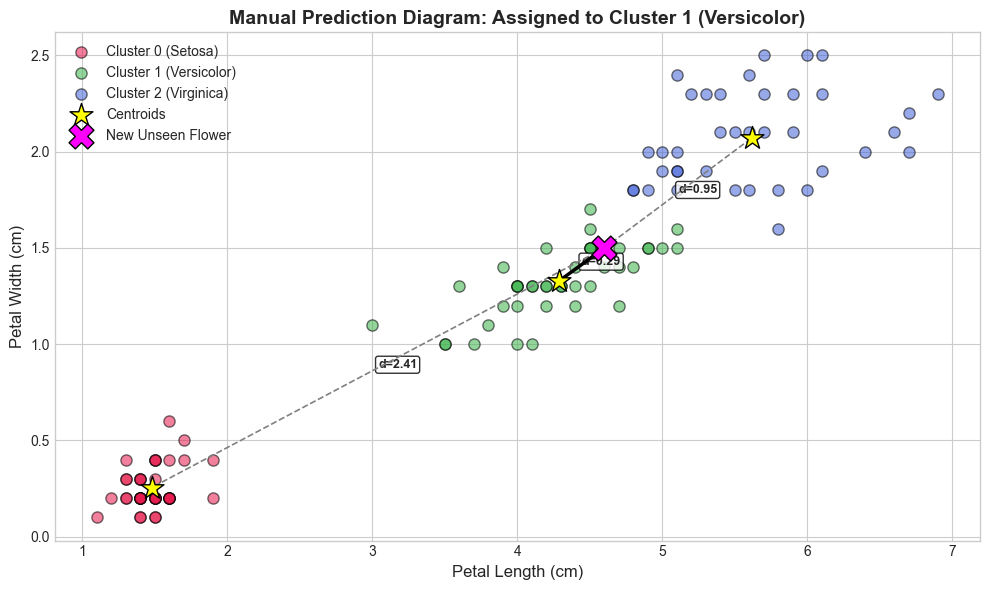

In [8]:
# 1. Define new unseen sample [Petal Length (cm), Petal Width (cm)]
new_sample = np.array([[4.6, 1.5]])

# 2. Scale using the training scaler
new_sample_scaled = scaler.transform(new_sample)

# 3. Predict cluster and calculate Euclidean distances to all centroids
predicted_cluster = final_kmeans.predict(new_sample_scaled)[0]
distances_scaled = np.linalg.norm(final_kmeans.cluster_centers_ - new_sample_scaled, axis=1)

species_names = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}
predicted_species = species_names[label_map[predicted_cluster]]

print("=== Manual Prediction Report ===")
print(f"Input Measurements : Petal Length = {new_sample[0,0]} cm, Petal Width = {new_sample[0,1]} cm")
for idx, dist in enumerate(distances_scaled):
    print(f"Distance to Cluster {idx} ({species_names[label_map[idx]]}): {dist:.4f}")
print(f"\n--> Final Assignment: Cluster {predicted_cluster} ({predicted_species})")

# 4. Visualize the Manual Prediction and Distance Vectors to Centroids
plt.figure(figsize=(10, 6))
colors = ['#e6194b', '#3cb44b', '#4363d8']

# Plot full dataset background
for i in range(3):
    pts = X_train[train_clusters == i]
    plt.scatter(pts[:, 0], pts[:, 1], s=65, c=colors[i], label=f'Cluster {i} ({species_names[label_map[i]]})', alpha=0.55, edgecolors='k')

# Plot Centroids
plt.scatter(centroids_original[:, 0], centroids_original[:, 1], s=300, c='yellow', marker='*', edgecolors='black', zorder=5, label='Centroids')

# Plot New Prediction Point
plt.scatter(new_sample[0, 0], new_sample[0, 1], s=320, c='magenta', marker='X', edgecolors='black', zorder=6, label='New Unseen Flower')

# Draw dashed lines from the new point to each centroid
for idx, centroid in enumerate(centroids_original):
    line_style = '-' if idx == predicted_cluster else '--'
    line_width = 2.5 if idx == predicted_cluster else 1.2
    line_color = 'black' if idx == predicted_cluster else 'gray'
    plt.plot(
        [new_sample[0, 0], centroid[0]],
        [new_sample[0, 1], centroid[1]],
        linestyle=line_style,
        linewidth=line_width,
        color=line_color,
        zorder=4
    )
    # Annotate scaled distance at midpoint
    mid_x = (new_sample[0, 0] + centroid[0]) / 2
    mid_y = (new_sample[0, 1] + centroid[1]) / 2
    plt.text(mid_x, mid_y, f"d={distances_scaled[idx]:.2f}", fontsize=9, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))

plt.title(f'Manual Prediction Diagram: Assigned to Cluster {predicted_cluster} ({predicted_species})', fontsize=14, fontweight='bold')
plt.xlabel('Petal Length (cm)', fontsize=12)
plt.ylabel('Petal Width (cm)', fontsize=12)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()